In [2]:
pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,StandardScaler,LabelEncoder,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from collections import Counter
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN



In [4]:
df = pd.read_csv(r"C:\Users\bkapa\Downloads\Fraud Detection Dataset.csv")

In [5]:
print(list(df.columns))

['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type', 'Time_of_Transaction', 'Device_Used', 'Location', 'Previous_Fraudulent_Transactions', 'Account_Age', 'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent']


# Partition

In [6]:
split_fraction = 0.70
partition = df.sample(frac=split_fraction, random_state=42)
len(partition)

35700

# Random

In [7]:
sample_random = df.sample(n=100)
sample_random.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
20268,T20269,4471,1106.10,ATM Withdrawal,19.0,Tablet,Los Angeles,0,29,10,UPI,0
42164,T42165,3921,1077.51,POS Payment,20.0,Tablet,Boston,1,97,13,Net Banking,0
47069,T47070,4898,2521.67,Online Purchase,4.0,Mobile,New York,3,32,12,Debit Card,0
18055,T18056,1787,1488.02,Bill Payment,8.0,Desktop,NaN,1,71,3,Credit Card,0
27793,T27794,2520,3504.91,Online Purchase,11.0,Mobile,Chicago,0,55,9,Credit Card,0


# Stratified

In [10]:
sample_stratified = (
    df.groupby("Location")
      .apply(lambda x: x.sample(frac=0.1))
)
sample_stratified.head()
#sample_stratified.count()
#print(sample_stratified["Location"].value_counts())

C:\Users\bkapa\AppData\Local\Temp\ipykernel_34300\3484807926.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(frac=0.1))


Transaction_ID  User_ID  Transaction_Amount Transaction_Type  \
Location                                                                      
Boston   28550         T28551     2083                 NaN  Online Purchase   
         15555         T15556     2756              489.90      POS Payment   
         28311         T28312     2620             1328.76   ATM Withdrawal   
         20054         T20055     4427             1251.48    Bank Transfer   
         17137         T17138     2280             2532.02      POS Payment   

                Time_of_Transaction Device_Used Location  \
Location                                                   
Boston   28550                  1.0      Mobile   Boston   
         15555                 16.0      Mobile   Boston   
         28311                 19.0      Mobile   Boston   
         20054                 21.0      Tablet   Boston   
         17137                  NaN      Tablet   Boston   

                Previous_Fraudulent_Transactions  Account_Age  \
Location                                                        
Boston   28550                                 2           16   
         15555                                 0           20   
         28311                                 2           71   
         20054                                 2          107   
         17137                                 0           15   

                Number_of_Transactions_Last_24H Payment_Method  Fraudulent  
Location                                                                    
Boston   28550                                7     Debit Card           0  
         15555                                1     Debit Card           0  
         28311                               13     Debit Card           0  
         20054                                6            NaN           0  
         17137                                7    Credit Card           0

# Task 1: Fix number of sample (500 only)

In [11]:
# stratified by Location, exactly 500 rows (rows with missing Location are left out)
d = df.dropna(subset=["Location"])
sample_500, _ = train_test_split(d, train_size=500, stratify=d["Location"], random_state=42)
print(len(sample_500))

500


# Task 2: Location-wise list/count

In [12]:
print(df["Location"].value_counts(dropna=False))
print(sample_500["Location"].value_counts())

Location
Boston           6149
New York         6110
Seattle          6104
Chicago          6071
Houston          6031
Los Angeles      6012
Miami            5991
San Francisco    5985
NaN              2547
Name: count, dtype: int64
Location
Chicago          63
New York         63
Boston           63
Seattle          63
Los Angeles      62
Miami            62
Houston          62
San Francisco    62
Name: count, dtype: int64


# Task 3: Equalize the location-wise count

In [13]:
# 62 per location x 8 locations = 496 (500 can't be split equally across 8)
sample_equal = df.groupby("Location").sample(n=62, random_state=42)
print(sample_equal["Location"].value_counts())

Location
Boston           62
Chicago          62
Houston          62
Los Angeles      62
Miami            62
New York         62
San Francisco    62
Seattle          62
Name: count, dtype: int64


# Cluster

In [18]:
locations = df["Location"].dropna().unique()
selected_locations = pd.Series(locations).sample(n=2, random_state=42)
sample_cluster = df[df["Location"].isin(selected_locations)]
sample_cluster.head(36)
#sample_cluster.count()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
16,T17,4171,3960.52,Bank Transfer,13.0,Tablet,Miami,2,68,8,Debit Card,0
17,T18,3919,2327.71,Online Purchase,20.0,NaN,Miami,4,21,1,Debit Card,0
20,T21,2685,973.51,Bill Payment,2.0,Mobile,New York,1,43,12,UPI,0
21,T22,4380,2553.98,ATM Withdrawal,3.0,Mobile,Miami,1,7,9,Net Banking,0
22,T23,1769,2222.86,POS Payment,14.0,Mobile,Miami,1,103,10,UPI,0
25,T26,4485,NaN,Online Purchase,17.0,Mobile,Miami,2,63,8,UPI,0
26,T27,3853,4065.44,Online Purchase,21.0,Tablet,New York,4,99,9,Net Banking,0
30,T31,3324,428.39,POS Payment,20.0,Desktop,New York,0,85,10,Credit Card,0
32,T33,1459,2212.25,Online Purchase,10.0,Desktop,New York,4,14,13,UPI,0


# Task 4: Sample from 5 most/least listed locations

In [19]:
counts = df["Location"].value_counts()
top5 = counts.head(5).index
bottom5 = counts.tail(5).index
print("Most listed :", top5.tolist())
print("Least listed:", bottom5.tolist())

sample_top5 = df[df["Location"].isin(top5)].sample(n=500, random_state=42)
sample_bottom5 = df[df["Location"].isin(bottom5)].sample(n=500, random_state=42)
print(sample_top5["Location"].value_counts())
print(sample_bottom5["Location"].value_counts())

Most listed : ['Boston', 'New York', 'Seattle', 'Chicago', 'Houston']
Least listed: ['Chicago', 'Houston', 'Los Angeles', 'Miami', 'San Francisco']
Location
Seattle     113
Chicago     109
Boston      100
Houston      98
New York     80
Name: count, dtype: int64
Location
Chicago          111
San Francisco    103
Los Angeles      101
Miami             98
Houston           87
Name: count, dtype: int64


# Data Selection

**1. Missing Value**

In [20]:
print(df.isna().sum())
num_cols = ["Transaction_Amount", "Time_of_Transaction"]
cat_cols = ["Device_Used", "Location", "Payment_Method"]
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
print(df.isna().sum().sum())

Transaction_ID                         0
User_ID                                0
Transaction_Amount                  2520
Transaction_Type                       0
Time_of_Transaction                 2552
Device_Used                         2473
Location                            2547
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                      2469
Fraudulent                             0
dtype: int64
0


**2. Identical Values**

In [21]:
print("Duplicate Transaction_IDs:", df["Transaction_ID"].duplicated().sum())
print("Fully identical rows:", df.duplicated().sum())
print("Constant columns:", [col for col in df.columns if df[col].nunique() == 1])
df = df.drop_duplicates(subset="Transaction_ID")
print(df.shape)

Duplicate Transaction_IDs: 1000
Fully identical rows: 881
Constant columns: []
(50000, 12)


**3. Correlation Analysis**

Number_of_Transactions_Last_24H    -0.003891
Previous_Fraudulent_Transactions    0.000634
Transaction_Amount                  0.004854
Account_Age                         0.005704
Time_of_Transaction                 0.005892
User_ID                             0.007373
Fraudulent                          1.000000
Name: Fraudulent, dtype: float64


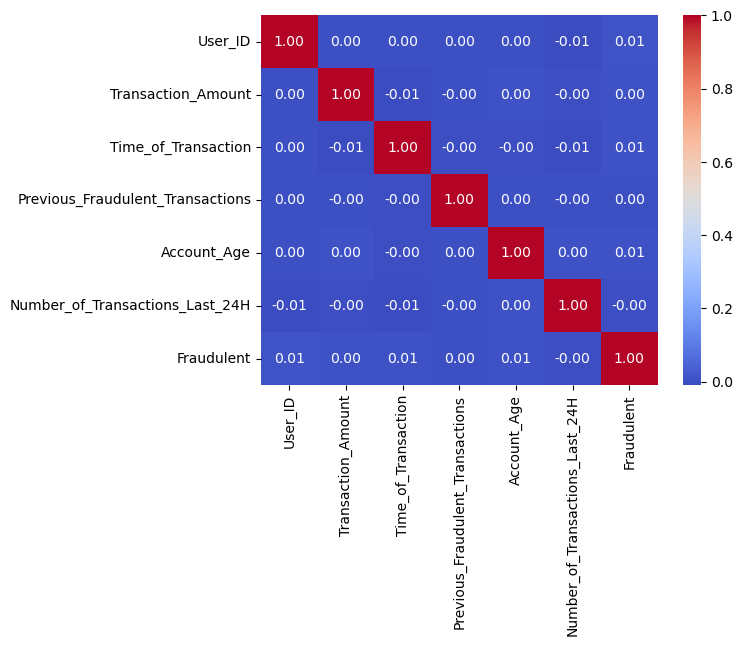

In [22]:
corr = df.corr(numeric_only=True)
print(corr["Fraudulent"].sort_values())
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

**4. Chi-Square Test**

In [25]:
X = pd.get_dummies(df.drop(columns=["Transaction_ID", "User_ID", "Fraudulent"]), dtype=int)
Y = df["Fraudulent"]
X_scaled = MinMaxScaler().fit_transform(X)   # chi2 needs non-negative values

from sklearn.feature_selection import SelectKBest, chi2
selector = SelectKBest(chi2, k="all")
selector.fit(X_scaled, Y)
chi_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print(chi_scores)

Location_Chicago                    4.750992
Location_Seattle                    4.299105
Device_Used_Tablet                  2.218758
Device_Used_Mobile                  2.017179
Transaction_Type_ATM Withdrawal     1.229673
Location_Houston                    0.943962
Transaction_Type_Online Purchase    0.913925
Location_Los Angeles                0.707304
Location_New York                   0.401848
Time_of_Transaction                 0.298404
Account_Age                         0.276370
Transaction_Type_Bank Transfer      0.194204
Transaction_Amount                  0.192765
Transaction_Type_POS Payment        0.187985
Number_of_Transactions_Last_24H     0.144835
Device_Used_Unknown Device          0.111730
Location_San Francisco              0.071918
Payment_Method_UPI                  0.050338
Location_Miami                      0.038359
Payment_Method_Invalid Method       0.036727
Location_Boston                     0.030214
Transaction_Type_Bill Payment       0.027410
Device_Use

# Split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, stratify=Y, random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.value_counts())

(35000, 27) (15000, 27)
Fraudulent
0    33278
1     1722
Name: count, dtype: int64


**Task 5:** ML Model

In [34]:
rf = __import__("sklearn.ensemble", fromlist=["RandomForestClassifier"]).RandomForestClassifier(random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
print(__import__("sklearn.metrics", fromlist=["classification_report"]).classification_report(y_test, pred, zero_division=0))
print(__import__("sklearn.metrics", fromlist=["confusion_matrix"]).confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97     14262
           1       0.00      0.00      0.00       738

    accuracy                           0.95     15000
   macro avg       0.48      0.50      0.49     15000
weighted avg       0.90      0.95      0.93     15000

[[14262     0]
 [  738     0]]


In [36]:
# Model 2: Random Forest after SMOTE
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
print(y_sm.value_counts())
from sklearn.ensemble import RandomForestClassifier
rf_sm = RandomForestClassifier(random_state=42, n_jobs=1)
rf_sm.fit(X_sm, y_sm)
pred_sm = rf_sm.predict(X_test)
print(__import__("sklearn.metrics", fromlist=["classification_report"]).classification_report(y_test, pred_sm, zero_division=0))
print(__import__("sklearn.metrics", fromlist=["confusion_matrix"]).confusion_matrix(y_test, pred_sm))

Fraudulent
0    33278
1    33278
Name: count, dtype: int64
              precision    recall  f1-score   support

           0       0.95      1.00      0.97     14262
           1       0.33      0.00      0.00       738

    accuracy                           0.95     15000
   macro avg       0.64      0.50      0.49     15000
weighted avg       0.92      0.95      0.93     15000

[[14260     2]
 [  737     1]]


# Result Analysis

In [37]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(10))

Transaction_Amount                  0.215879
Account_Age                         0.179329
Time_of_Transaction                 0.131147
Number_of_Transactions_Last_24H     0.114782
Previous_Fraudulent_Transactions    0.069339
Device_Used_Desktop                 0.017382
Device_Used_Mobile                  0.017114
Device_Used_Tablet                  0.016846
Payment_Method_UPI                  0.016594
Transaction_Type_Bank Transfer      0.015727
dtype: float64


**Analysis**
- Dataset: 51,000 rows; 1,000 duplicate Transaction_IDs removed, ~2,500 missing values each in Amount, Time, Device, Location, Payment Method imputed (median / mode). Fraud is only ~5% of rows (imbalanced).
- Correlation of every numeric feature with `Fraudulent` is ~0 (|r| < 0.01), and chi-square scores are all low, so no feature separates fraud strongly. Location (Chicago, Seattle) scored highest, but weakly.
- Random Forest on raw data predicts everything as non-fraud: 95% accuracy but 0% fraud recall (accuracy is misleading on imbalanced data).
- SMOTE balances the training data but barely helps: fraud recall stays ~0%. The features carry almost no fraud signal, so resampling cannot fix it.
- Random Forest importances favour Transaction_Amount and Account_Age, but these are small and not predictive.
- Next steps: better features (user history, amount vs user average), threshold tuning, class weights, and judging by recall / PR-AUC rather than accuracy.